# SeismicDataset. Подготовка сейсмического датасета #

## 1.7. Сплайновые границы и сетки Fidesys для ECVB ##

Можно ли заменить ступенчатые границы сплайнами на всех 30 000 ECVB, сохранив топологию и общий порядок узлов источников? Генератор проверен на пяти ID. По ним рассматриваем два разных способа построения границ и условия перехода к серии.

In [1]:
from IPython.display import Image, display

from scripts.project_paths import PROJECT_ROOT as ROOT
from scripts.reporting import mapping, number, read_json, sequence

### Единая модель в четырёх представлениях ###

Плоскопараллельная EFVB допускает регулярную сетку и послойную карту материала. Для ECVB исходный растр задаёт пары скоростей и связные регионы. У сквозных слоёв аппроксимируются глубины горизонтов, в остальных моделях строится общий граф сплайнов. Прямые стороны растровых прямоугольников закрепляются до сглаживания. Обе стороны контакта используют одну CAD-кривую. В №00065 это сохранило два верхних включения размером 640×70 и 540×70 м.

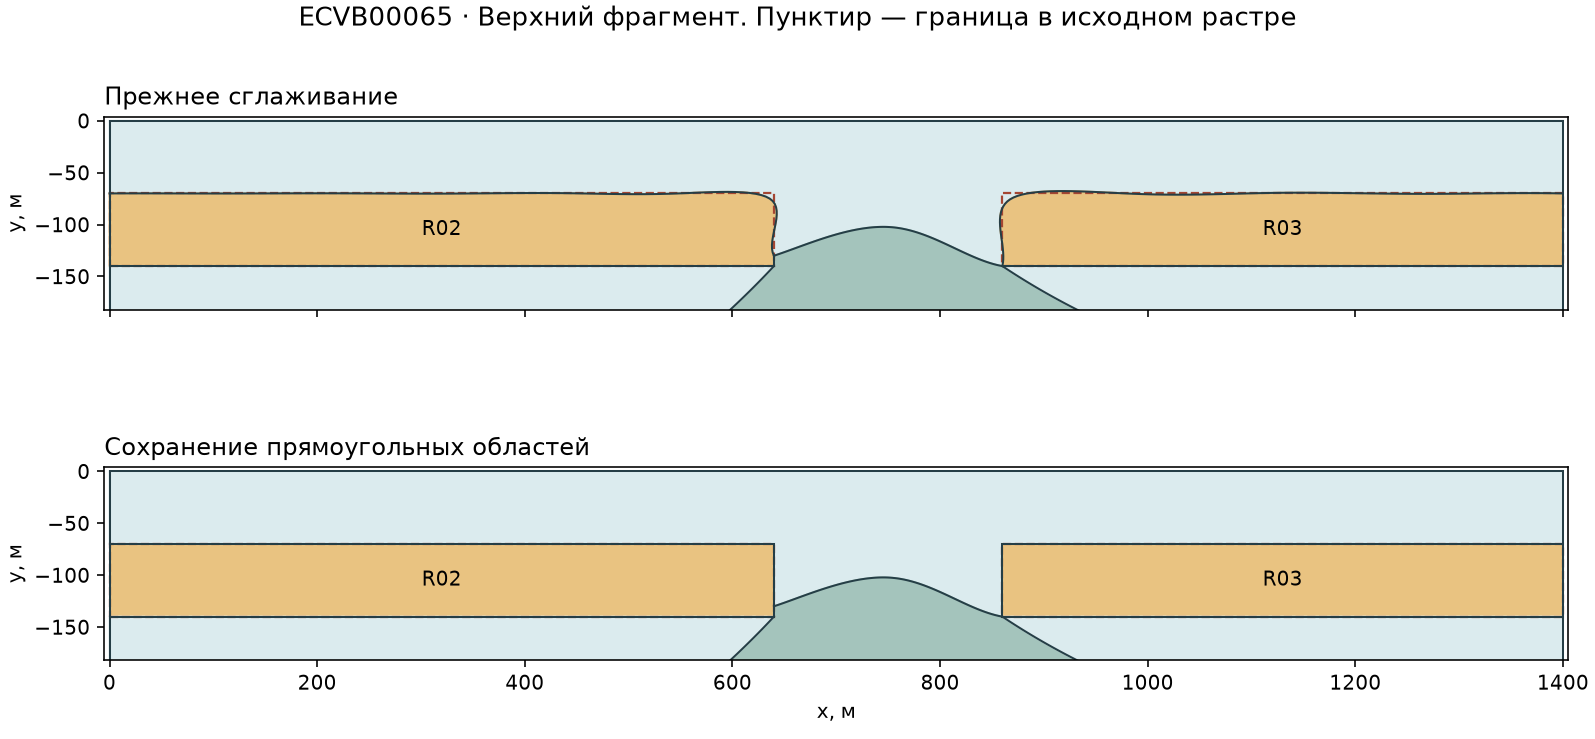

In [2]:
display(Image(filename=str(ROOT / "img/dev_1_6_p67s_showcase/cubit_ecvb00065_corners_v2/ECVB00065_corners.png"), width=850))

### Что проверено на пяти ECVB ###

Один ID связывает cartesian.npz, автономный журнал geometry.jou, материализованный FC с блоком на регион и sem_input.npz с Q2-геометрией и картой материала. Рядом находятся точные сплайны и манифест с SHA256. Проверяются граф контактов, положительность якобиана во всём элементе, материалы и верхние 140 рёбер по 10 м. Таблица читает окончательные манифесты. Последний столбец — максимальное выборочное расстояние квадратичного ребра до CAD, в метрах.

In [3]:
audit_path = (ROOT / "data/dev_1_6_fidesys_mesh/dataset_pilot_checks_v1.json")
audit = read_json(audit_path)
for model in sequence(audit["models"]):
    row = mapping(model)
    manifest = read_json(audit_path.parent / str(row["manifest"]))
    quality = mapping(manifest["mesh_quality"])
    error = mapping(quality["sampled_interface_error_to_own_cad_m"])
    print(f"№{int(number(row['id'])):05d}   {row['regions']} регионов   {row['core_elements']} QUAD8   {number(error['max']):.4f} м")

№00000   26 регионов   10414 QUAD8   0.5371 м
№00065   8 регионов   9776 QUAD8   0.0218 м
№12404   4 регионов   9660 QUAD8   0.0029 м
№15000   36 регионов   8634 QUAD8   0.4746 м
№29999   20 регионов   9332 QUAD8   0.0844 м


### От Q2 к узлам источников ###

На диске сохраняется только ядро. Контроллер продолжает граничный материал в PML, строит GLL-узлы p6 и нумерует полный верх слева направо от 0 до 1260. Семь источников при x=100,300,…,1300 м получают ID 270,390,…,990. На пяти пилотах это проверено на CPU. Максимум отклонения ребра 0,537 м принят для №00000. Для №00065 и №15000 повторное построение из журнала воспроизвело сеточную часть FC побитово. [Открыть ролик](img/dev_1_6_p67s_showcase/render_v2/ECVB00065/linear/x0700/velocity.mp4) показывает поле от центрального источника на прежней сетке №00065 из демонстрационной серии.

### Геометрия, качество и отказы построения ###

На ECVB12404 сквозные слои идут в одном порядке в каждом столбце. Для такой модели можно аппроксимировать высоту каждого горизонта как функцию x. На ECVB00000 и ECVB00065 приходится выделять связные области и строить граф их контактов. Сторона прямоугольника и длинное прямое ребро с выраженным углом выделяются до подбора сплайна. Закрепление вершин оставляет излом там, где геометрия его требует. В каждом журнале Fidesys общая граница создаётся один раз, а при экспорте FC каждая область получает собственный блок и материал.

На №00065 сравнили два маршрута: треугольную затравочную сетку с последующим разбиением и построение четырёхугольников по поверхностям в Fidesys. Рисунок показывает распределение scaled Jacobian в ядре. Это мера формы элемента; расстояние ребра QUAD8 до CAD характеризует уже другую ошибку. В генераторе положительность якобиана проверяется на всём элементе. Расстояние до CAD оценивается выборочно в 21 точке каждого интерфейсного ребра.

В сложном №15000 первая сетка имела инверсии. Локальное перестроение трёх поверхностей с размером 7,5 м дало положительные элементы, но минимальный scaled Jacobian здесь остался около 0,095. У №12404 минимум около 0,885. Поэтому удачный слоистый пилот недостаточен для оценки выхода годных сеток на всём ECVB. [Протокол генератора и таблица пилотов](docs/dev_1_6_fidesys_mesh.md).

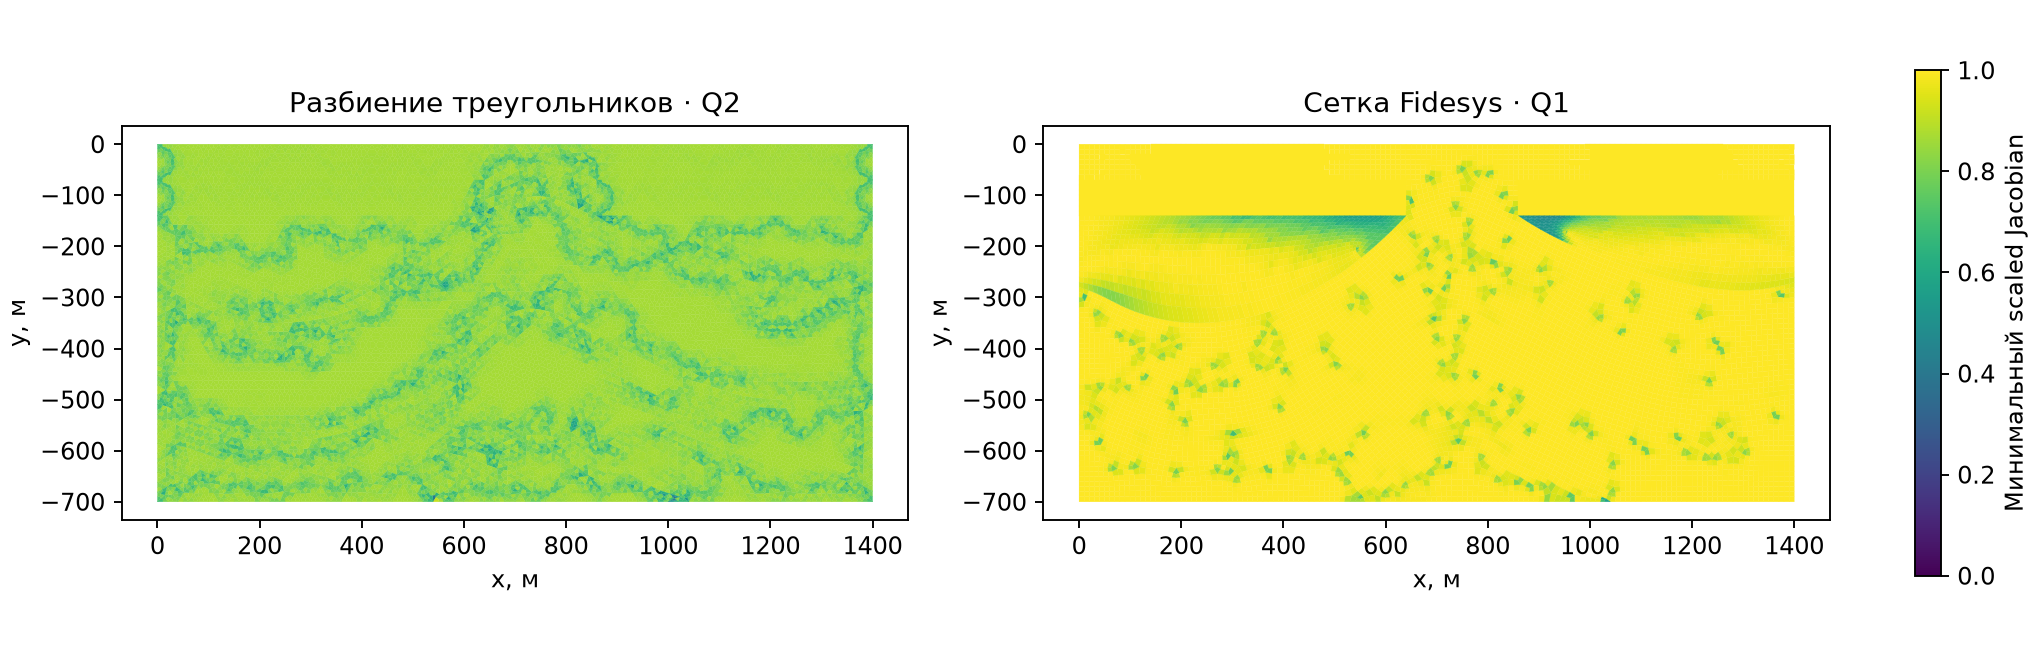

In [4]:
display(Image(filename=str(ROOT / "img/dev_1_6_p67s_showcase/fc_mesh_quality_v1/scaled_jacobian.png"), width=850))

### Что остаётся до выпуска ###

К общему набору главы 1.6 для каждого ECVB добавляются точные кривые и стыки, автономный geometry.jou и материализованная сетка Fidesys. Исходный растр 70 × 70 нужен для проверки происхождения. Целевая карта 140 × 70 описывает уже сглаженную модель. Для каждого центра декартовой ячейки предстоит определить содержащий Q2-элемент, используя его реальную криволинейную карту, и выбрать пару Vp, Vs этого элемента. На границе двух материалов требуется единое правило разрешения совпадений. Поиск ближайшего центра SEM-элемента может выбрать материал по другую сторону кривой.

Пять комплектов геометрии приняты под исходными ID. Открыты проверка проекции по центрам на всём классе, обработка остальных топологий, статистика отказов и сейсмограммы для 13 источников. Симметрия плоской среды в общем ECVB отсутствует. Отклонение 0,537 м, согласованное для №00000 между Q2-ребром и CAD, не служит универсальной оценкой изменения исходного растра или волнового поля.